In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./AI_workforce_displacement.csv")
df.head()

,country,income_group,year,industry_sector,sector_automation_risk_score,gdp_per_capita_usd,ai_adoption_index,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created,net_workforce_change_pct,ai_cited_layoff_announcements,ai_skill_wage_premium_pct,reskilling_programs_count,govt_ai_policy_score_1_to_10,ai_tool_adoption_pct
0,United States,High Income,2020,Technology & Software,0.382,63514,0.830,0.0406,0.0348,-0.0058,32,0.311,52,6.4,0.280
1,United States,High Income,2020,Finance & Banking,0.608,63514,0.817,0.0517,0.0423,-0.0094,51,0.304,39,6.5,0.559
2,United States,High Income,2020,Healthcare & Life Sciences,0.198,63514,0.816,0.0176,0.0168,-0.0008,4,0.278,37,6.8,0.202
3,United States,High Income,2020,Manufacturing & Industry,0.720,63514,0.818,0.0924,0.0642,-0.0282,47,0.268,50,6.8,0.655
4,United States,High Income,2020,Retail & E-Commerce,0.676,63514,0.828,0.0667,0.0374,-0.0293,31,0.313,37,6.2,0.542


In [3]:
df.columns

Index(['country', 'income_group', 'year', 'industry_sector',
       'sector_automation_risk_score', 'gdp_per_capita_usd',
       'ai_adoption_index', 'pct_sector_workforce_displaced',
       'pct_sector_workforce_new_roles_created', 'net_workforce_change_pct',
       'ai_cited_layoff_announcements', 'ai_skill_wage_premium_pct',
       'reskilling_programs_count', 'govt_ai_policy_score_1_to_10',
       'ai_tool_adoption_pct'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 15 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   country                                 20800 non-null  object 
 1   income_group                            20800 non-null  object 
 2   year                                    20800 non-null  int64  
 3   industry_sector                         20800 non-null  object 
 4   sector_automation_risk_score            20800 non-null  float64
 5   gdp_per_capita_usd                      20800 non-null  int64  
 6   ai_adoption_index                       20800 non-null  float64
 7   pct_sector_workforce_displaced          20800 non-null  float64
 8   pct_sector_workforce_new_roles_created  20800 non-null  float64
 9   net_workforce_change_pct                20800 non-null  float64
 10  ai_cited_layoff_announcements           20800 non-null  in

In [5]:
df.describe()

,year,sector_automation_risk_score,gdp_per_capita_usd,ai_adoption_index,pct_sector_workforce_displaced,pct_sector_workforce_new_roles_created,net_workforce_change_pct,ai_cited_layoff_announcements,ai_skill_wage_premium_pct,reskilling_programs_count,govt_ai_policy_score_1_to_10,ai_tool_adoption_pct
count,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000,20800.000000
mean,2022.769231,0.537881,21003.330769,0.692148,0.056155,0.035631,-0.020524,88.346538,0.361570,34.497981,5.370067,0.372712
std,1.887406,0.190345,22048.862955,0.161194,0.044811,0.036586,0.015327,85.198076,0.094132,22.688847,1.566616,0.166875
min,2020.000000,0.151000,879.000000,0.169000,0.001800,0.000300,-0.140300,0.000000,0.063000,2.000000,1.100000,0.037000
25%,2021.000000,0.379000,3456.500000,0.591000,0.023300,0.009800,-0.028200,24.000000,0.293000,13.000000,4.000000,0.231000
50%,2023.000000,0.580000,10635.000000,0.720000,0.043400,0.021900,-0.016400,63.000000,0.366000,30.000000,5.400000,0.365000
75%,2024.000000,0.698000,40528.500000,0.821000,0.074900,0.049400,-0.009100,126.000000,0.435000,53.000000,6.800000,0.498000
max,2026.000000,0.855000,99074.000000,0.963000,0.300000,0.279100,-0.000300,603.000000,0.610000,92.000000,8.800000,0.881000


In [6]:
df.isnull().sum()

country                                   0
income_group                              0
year                                      0
industry_sector                           0
sector_automation_risk_score              0
gdp_per_capita_usd                        0
ai_adoption_index                         0
pct_sector_workforce_displaced            0
pct_sector_workforce_new_roles_created    0
net_workforce_change_pct                  0
ai_cited_layoff_announcements             0
ai_skill_wage_premium_pct                 0
reskilling_programs_count                 0
govt_ai_policy_score_1_to_10              0
ai_tool_adoption_pct                      0
dtype: int64

## Conditional Statement

In [7]:
def riskscore(score):
    if score >= 0.7:
        return 'High'
    elif score >= 0.5:
        return 'Moderate'
    elif score >= 0.3:
        return 'Low'
    else:
        return 'Extremely Low'

In [8]:
# I Creating a new column name df[“Risk_Evaluation”] by apply this function to the “sector_automation_risk_score” 

In [9]:
df['Risk_Evaluation'] = df['sector_automation_risk_score'].apply(riskscore)

## Label Encoding

In [10]:
df["Risk_Evaluation"] = df["Risk_Evaluation"].map({'Low':0, 'Moderate':1, 'High':2, 'Extremely Low':3})

In [11]:
x = df[['sector_automation_risk_score', 'gdp_per_capita_usd',
       'ai_adoption_index', 'pct_sector_workforce_displaced',
       'pct_sector_workforce_new_roles_created', 'net_workforce_change_pct',
       'ai_cited_layoff_announcements', 'ai_skill_wage_premium_pct',
       'reskilling_programs_count', 'govt_ai_policy_score_1_to_10',
       'ai_tool_adoption_pct']]
y = df["Risk_Evaluation"]

In [12]:
from sklearn.feature_selection import SelectKBest,f_classif

In [13]:
skb = SelectKBest(f_classif, k =5)
select = skb.fit_transform(x,y)
column_name = x.columns[skb.get_support()]
column_name

Index(['sector_automation_risk_score', 'pct_sector_workforce_displaced',
       'net_workforce_change_pct', 'ai_cited_layoff_announcements',
       'ai_tool_adoption_pct'],
      dtype='object')

In [14]:
x_new = df[['sector_automation_risk_score', 'pct_sector_workforce_displaced',
       'net_workforce_change_pct', 'ai_cited_layoff_announcements',
       'ai_tool_adoption_pct']]

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
xtrain, xtest, ytrain, ytest = train_test_split(x_new,y, test_size = 0.2, random_state = 42)
xtrain.shape, xtest.shape, ytrain.shape, ytest.shape

((16640, 5), (4160, 5), (16640,), (4160,))

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
scale = StandardScaler()
xtrain_scale = scale.fit_transform(xtrain)
xtest_scale = scale.transform(xtest)

In [19]:
xtrain_scale[0:4], xtest_scale[0:4]

(array([[ 0.9445878 ,  2.39652286, -1.54654316,  1.95014415,  2.43669802],
        [ 0.75515117, -0.99600095,  0.70245697, -0.89956014, -1.3209172 ],
        [-1.57070962, -1.10803938,  1.07511106, -1.00598064, -1.68107201],
        [ 0.70779202, -0.70246025,  0.65015464, -0.48570267, -0.2884734 ]]),
 array([[-0.54985669, -0.85707329,  0.57170115, -0.80496415, -0.97877013],
        [ 0.34470515, -0.68229333,  0.36249183,  0.20011828, -0.16241922],
        [ 1.28136402,  3.50570336, -4.49508693,  1.79642567,  2.01651741],
        [ 0.78146182, -0.66212641,  0.33634067, -0.80496415,  0.00565303]]))

In [20]:
from sklearn.linear_model import LogisticRegression

In [21]:
log = LogisticRegression()
model = log.fit(xtrain_scale,ytrain)
model

LogisticRegression()

In [22]:
y_pred = model.predict(xtest_scale)
y_pred

array([0, 1, 2, ..., 1, 1, 2])

In [23]:
y_compare = pd.DataFrame(ytest)
y_compare['Predicted'] = y_pred
y_compare = y_compare.reset_index()
y_compare.drop('index', axis = 1)

,Risk_Evaluation,Predicted
0,0,0
1,1,1
2,2,2
3,1,1
4,1,1
...,...,...
4155,1,1
4156,1,1
4157,1,1
4158,1,1


In [24]:
xt = xtest.reset_index(drop = True)
xt

,sector_automation_risk_score,pct_sector_workforce_displaced,net_workforce_change_pct,ai_cited_layoff_announcements,ai_tool_adoption_pct
0,0.434,0.0179,-0.0118,20,0.210
1,0.604,0.0257,-0.0150,105,0.346
2,0.782,0.2126,-0.0893,240,0.709
3,0.687,0.0266,-0.0154,20,0.374
4,0.567,0.0553,-0.0255,53,0.436
...,...,...,...,...,...
4155,0.628,0.1291,-0.0065,153,0.580
4156,0.657,0.0530,-0.0099,59,0.487
4157,0.626,0.1079,-0.0483,255,0.455
4158,0.699,0.0424,-0.0195,33,0.408


In [25]:
prob = model.predict_proba(xtest_scale)
prob

array([[9.93221268e-01, 6.00230561e-03, 2.46738824e-17, 7.76426327e-04],
       [2.91047321e-04, 9.99702665e-01, 6.28767014e-06, 2.46346542e-13],
       [5.05367275e-14, 5.36654552e-05, 9.99946335e-01, 5.43242561e-29],
       ...,
       [1.11507388e-05, 9.99898217e-01, 9.06320146e-05, 2.83509948e-17],
       [1.19089817e-06, 5.73439292e-01, 4.26559518e-01, 5.29995778e-17],
       [1.94256434e-12, 2.42580497e-04, 9.99757420e-01, 1.63382133e-25]])

In [26]:
x = pd.DataFrame(prob[:, 0], columns=["Probability"])
x

,Probability
0,9.932213e-01
1,2.910473e-04
2,5.053673e-14
3,4.468521e-06
4,9.031619e-03
...,...
4155,3.980174e-05
4156,1.550625e-05
4157,1.115074e-05
4158,1.190898e-06


In [27]:
xtest.reset_index(drop=True)

,sector_automation_risk_score,pct_sector_workforce_displaced,net_workforce_change_pct,ai_cited_layoff_announcements,ai_tool_adoption_pct
0,0.434,0.0179,-0.0118,20,0.210
1,0.604,0.0257,-0.0150,105,0.346
2,0.782,0.2126,-0.0893,240,0.709
3,0.687,0.0266,-0.0154,20,0.374
4,0.567,0.0553,-0.0255,53,0.436
...,...,...,...,...,...
4155,0.628,0.1291,-0.0065,153,0.580
4156,0.657,0.0530,-0.0099,59,0.487
4157,0.626,0.1079,-0.0483,255,0.455
4158,0.699,0.0424,-0.0195,33,0.408


In [28]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [29]:
acc = accuracy_score(ytest,y_pred)
acc

0.9855769230769231

In [30]:
CM = confusion_matrix(ytest,y_pred)
CM

array([[ 870,    3,    0,   31],
       [   5, 1424,    0,    0],
       [   0,   21,  999,    0],
       [   0,    0,    0,  807]])

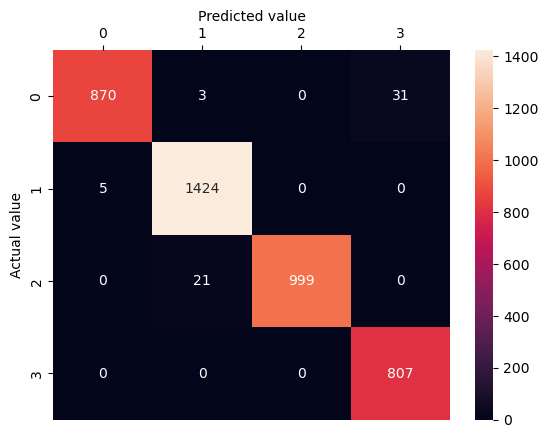

In [31]:
sns.heatmap(CM,annot = True, fmt = "d")
plt.xlabel("Predicted value")
plt.ylabel("Actual value")
plt.gca().xaxis.set_label_position("top")
plt.gca().xaxis.tick_top()
plt.savefig('cm')
plt.show()

In [32]:
cr = classification_report(ytest,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.99      0.96      0.98       904
           1       0.98      1.00      0.99      1429
           2       1.00      0.98      0.99      1020
           3       0.96      1.00      0.98       807

    accuracy                           0.99      4160
   macro avg       0.99      0.98      0.98      4160
weighted avg       0.99      0.99      0.99      4160



In [33]:
Risk = y_compare['Risk_Evaluation'].value_counts()
Risk

Risk_Evaluation
1    1429
2    1020
0     904
3     807
Name: count, dtype: int64

In [34]:
Predicted = y_compare['Predicted'].value_counts()
Predicted

Predicted
1    1448
2     999
0     875
3     838
Name: count, dtype: int64

In [35]:
column = [Risk, Predicted]
metric = pd.DataFrame(column, index = [['Risk', 'Predicted']])
metric = metric.rename(columns = {1: "class 1", 2: "class 2", 0: "class 0", 3: "class 3"})
metric

,class 1,class 2,class 0,class 3
Risk,1429,1020,904,807
Predicted,1448,999,875,838


<Figure size 700x500 with 0 Axes>

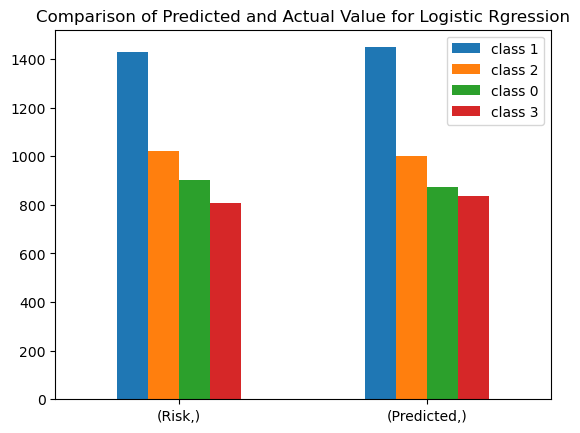

In [38]:
plt.figure(figsize = (7,5))
metric.plot(kind = "bar")
plt.title("Comparison of Predicted and Actual Value for Logistic Rgression")
plt.xticks(rotation=0)
plt.savefig('bar')
plt.show()